# AutoMetrics — Brand Price Analysis & Comparison

## Research Question
How do vehicle prices differ across car brands, and do those
differences remain when comparing similar types of vehicles?

Our goal is to compare vehicle prices across brands and investigate
how body type, performance, and safety features relate to pricing.

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#Load our group's cleaned vehicle dataset

#Locate the cleaned dataset from either notebook or project folder
data_path = Path("../data/processed/cars_dataset_cleaned.xlsx")

if not data_path.exists():
    data_path = Path("data/processed/cars_dataset_cleaned.xlsx")

if not data_path.exists():
    raise FileNotFoundError("Cleaned dataset not found.")

df = pd.read_excel(data_path)

#Confirm that the data loaded correctly
print("Dataset shape:", df.shape)
print("\nAvailable brands:")
print(sorted(df["make"].unique()))

print("\nVehicle body types:")
print(sorted(df["body_type"].unique()))

df.head()


Dataset shape: (100000, 26)

Available brands:
['Audi', 'BMW', 'Chevrolet', 'Ford', 'Honda', 'Hyundai', 'Kia', 'Lexus', 'Mazda', 'Mercedes-Benz', 'Nissan', 'Toyota', 'Volkswagen']

Vehicle body types:
['Convertible', 'Coupe', 'Crossover', 'Hatchback', 'Minivan', 'Pickup', 'SUV', 'Sedan', 'Van']


,vehicle_id,make,model,model_variant,model_year,vehicle_year,vehicle_age,body_type,brand_reputation_score,brand_reliability_score,...,torque_to_weight_ratio,handling_score,acceleration_score,braking_score,performance_score,reliability_score,original_price,msrp,total_feature_count,safety_feature_count
0,V00000001,BMW,i4,i4 RS,2020,2020,6,Sedan,88,78,...,311.439026,35.2,71.1,94.9,65.4,72.3,54950.99,56204.07,31,12
1,V00000002,Chevrolet,Equinox,Equinox SE,2016,2016,10,SUV,78,76,...,155.944885,35.9,77.3,57.8,66.2,52.7,24526.91,25741.61,21,9
2,V00000003,Kia,Sportage,Sportage M Sport,2024,2024,2,SUV,83,86,...,163.426372,41.1,78.3,86.0,65.9,78.2,26483.37,27482.64,18,8
3,V00000004,Hyundai,Ioniq 5,Ioniq 5 Sport,2015,2015,11,SUV,84,87,...,162.831227,40.3,60.7,73.3,62.4,71.6,53048.43,53061.91,37,15
4,V00000005,Honda,Accord,Accord GT,2022,2022,4,Sedan,90,92,...,262.573882,40.8,77.5,68.2,62.0,92.3,29120.61,29362.80,19,7



## Dataset and Preparation

This analysis uses the AutoMetrics cleaned vehicle dataset,
which contains 100,000 vehicle records and 26 columns.

The dataset was originally obtained from Kaggle and prepared
by our group before this analysis.

During cleaning:
- Duplicate records were checked.
- Missing prices were filled using median values.
- Missing reliability scores and model variants were handled.
- The cleaned dataset was saved separately from the original.

We use `original_price` for all price comparisons to stay
consistent with the group's initial exploratory analysis.

The dataset's currency and collection methodology have not
been independently verified. Therefore, prices are reported
in dataset units rather than assuming a specific currency.


## 1. Brand Price Comparison

We first compare vehicle prices across all 13 brands in the
dataset to see which brands have higher or lower typical prices.

We use the median price because it is less affected by unusually
expensive vehicles than the mean. We also include the number
of vehicles for each brand to understand the sample sizes.

In [10]:

#Calculate price statistics for each car brand
brand_prices = df.groupby("make")["original_price"].agg(
    vehicle_count="count",
    median_price="median",
    mean_price="mean"
)

#Sort brands from highest to lowest median price
brand_prices = brand_prices.sort_values(
    by="median_price",
    ascending=False
)

#Display the results rounded to two decimal places
brand_prices.round(2)


,vehicle_count,median_price,mean_price
make,,,
Mercedes-Benz,6031,64531.60,75323.95
BMW,5395,62006.36,66043.85
Audi,4334,52380.66,63672.39
Lexus,3832,47191.52,57276.35
Chevrolet,9934,33496.23,38371.38
Volkswagen,7910,33462.71,33554.13
Ford,12543,32426.73,31758.89
Toyota,13085,31097.08,37181.98
Kia,6757,30304.02,31780.48


### Visualization 1: Median Vehicle Price by Brand

This chart compares the median original price across all 13 brands.
We use median prices to reduce the influence of unusually expensive
vehicles and show sample sizes to provide context for each comparison.

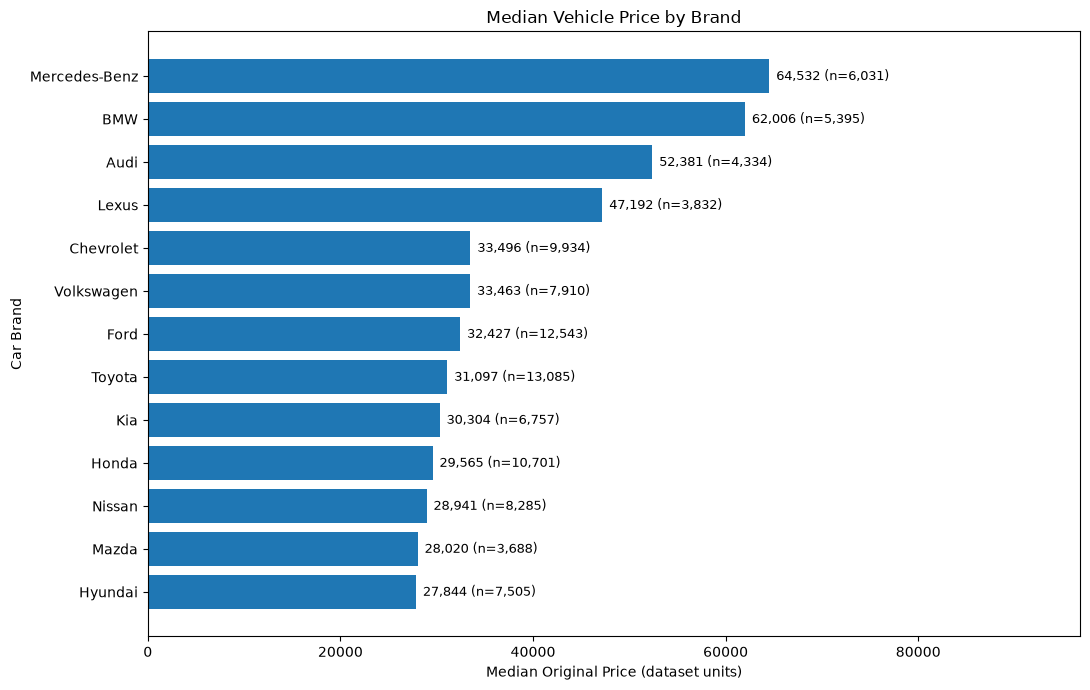

In [11]:

#Sort brands from lowest to highest median price
plot_data = brand_prices.sort_values("median_price")

#Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data.index,
    plot_data["median_price"]
)

#Show median price and sample size for each brand
labels = [
    f"{price:,.0f} (n={count:,})"
    for price, count in zip(
        plot_data["median_price"],
        plot_data["vehicle_count"]
    )
]

ax.bar_label(bars, labels=labels, padding=5, fontsize=9)

#Add chart title and axis labels
ax.set_title("Median Vehicle Price by Brand")
ax.set_xlabel("Median Original Price (dataset units)")
ax.set_ylabel("Car Brand")

#Start the price axis at zero and leave room for labels
ax.set_xlim(0, plot_data["median_price"].max() * 1.5)

plt.tight_layout()
plt.show()



### Findings: Brand Price Comparison

Mercedes-Benz has the highest median original price at approximately
64,532, followed by BMW at 62,006 and Audi at 52,381. Hyundai has the
lowest median price at approximately 27,844.

The results show a noticeable difference in typical prices across
brands. Mercedes-Benz's median price is more than twice Hyundai's,
suggesting that brands occupy different price ranges in this dataset.

However, these comparisons include all vehicle body types. Some
brands may have more SUVs, luxury models, or performance vehicles
than others, which could contribute to their higher prices.

Therefore, we cannot conclude that the brand name alone causes the
price difference. Our next step is to compare brands within the same
vehicle categories to make the comparisons more meaningful.

Note: Prices are reported in dataset units, and some originally
missing prices were filled during data cleaning.


## 2. Brand Prices Within Vehicle Body Types

To make the comparisons more meaningful, we separate SUVs and
sedans before comparing prices across brands.

This helps us investigate whether the overall brand price
differences remain when we account for vehicle body type.

In [12]:

#Select only SUVs and sedans
selected_vehicles = df[
    df["body_type"].isin(["SUV", "Sedan"])
]

#Calculate price statistics by body type and brand
body_type_prices = selected_vehicles.groupby(
    ["body_type", "make"]
)["original_price"].agg(
    vehicle_count="count",
    median_price="median"
).reset_index()

#Display SUV comparisons
print("SUV Price Comparison")
display(
    body_type_prices[
        body_type_prices["body_type"] == "SUV"
    ].sort_values(
        "median_price", ascending=False
    ).round(2)
)

#Display sedan comparisons
print("Sedan Price Comparison")
display(
    body_type_prices[
        body_type_prices["body_type"] == "Sedan"
    ].sort_values(
        "median_price", ascending=False
    ).round(2)
)


SUV Price Comparison


,body_type,make,vehicle_count,median_price
9,SUV,Mercedes-Benz,2344,74954.92
1,SUV,BMW,1611,65209.33
7,SUV,Lexus,1569,52979.84
0,SUV,Audi,1783,50547.25
12,SUV,Volkswagen,2382,41929.39
2,SUV,Chevrolet,3946,40502.24
5,SUV,Hyundai,3772,38558.35
11,SUV,Toyota,3957,38109.73
8,SUV,Mazda,1812,34468.58
3,SUV,Ford,4971,34407.42


Sedan Price Comparison


,body_type,make,vehicle_count,median_price
22,Sedan,Mercedes-Benz,2463,83885.07
14,Sedan,BMW,2771,60339.87
13,Sedan,Audi,1686,45545.98
20,Sedan,Lexus,1061,43439.62
19,Sedan,Kia,1296,36508.24
25,Sedan,Volkswagen,2347,30113.55
16,Sedan,Ford,1276,24874.76
17,Sedan,Honda,2412,24873.09
24,Sedan,Toyota,2524,24841.86
21,Sedan,Mazda,751,24590.40


### Visualization 2: Median SUV and Sedan Prices by Brand

This chart compares median original prices for SUVs and sedans
within each brand. Separating the vehicle types allows us to
investigate whether brand pricing differences remain within
the same category.

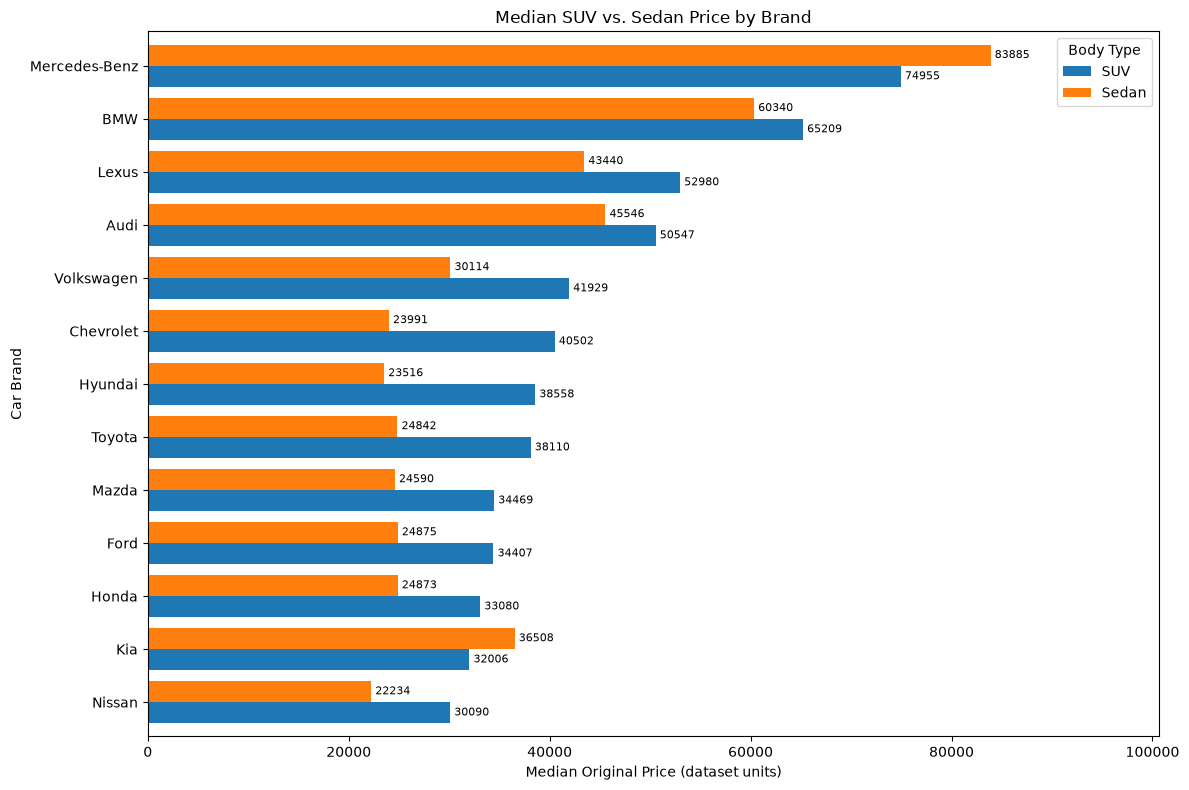

In [13]:

#Organize SUV and sedan median prices by brand
price_comparison = body_type_prices.pivot(
    index="make",
    columns="body_type",
    values="median_price"
)

#Sort brands by SUV median price
price_comparison = price_comparison.sort_values("SUV")

#Create side-by-side horizontal bars
fig, ax = plt.subplots(figsize=(12, 8))

price_comparison[["SUV", "Sedan"]].plot(
    kind="barh",
    ax=ax,
    width=0.8
)

#Add price labels to each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)

#Add title and labels
ax.set_title("Median SUV vs. Sedan Price by Brand")
ax.set_xlabel("Median Original Price (dataset units)")
ax.set_ylabel("Car Brand")
ax.legend(title="Body Type")

#Leave room for price labels
ax.set_xlim(0, price_comparison.max().max() * 1.2)

plt.tight_layout()
plt.show()



### Findings: SUV vs. Sedan Price Comparison

After separating SUVs and sedans, Mercedes-Benz still has the
highest median original price in both categories. Its median SUV
price is approximately 74,955, compared with Toyota at 38,110.

The differences also appear among sedans, where Mercedes-Benz
has a median price of 83,885 compared with Toyota at 24,842.

For most brands, SUVs have higher median prices than sedans.
However, Mercedes-Benz and Kia show the opposite pattern.

These results suggest that vehicle body type alone does not
account for the pricing differences between brands.

However, vehicles within the same body type can still differ
in model, performance, age, and included features. These are
observed associations, not evidence that brand identity causes
a particular price.


## 3. Performance and Safety Features vs. Price

This analysis examines whether original vehicle prices are
associated with performance scores and safety feature counts.

We calculate correlations for the overall dataset, SUVs,
and sedans to see whether these relationships differ by
vehicle category.

In [14]:

#Columns used for the correlation analysis
columns = [
    "original_price",
    "performance_score",
    "safety_feature_count"
]

#Compare correlations across vehicle groups
groups = {
    "All Vehicles": df,
    "SUVs": df[df["body_type"] == "SUV"],
    "Sedans": df[df["body_type"] == "Sedan"]
}

for group_name, group_data in groups.items():
    correlations = group_data[columns].corr()

    print(f"\n{group_name} (n={len(group_data):,})")

    print(
        correlations["original_price"]
        .drop("original_price")
        .round(3)
    )



All Vehicles (n=100,000)
performance_score       0.358
safety_feature_count    0.488
Name: original_price, dtype: float64

SUVs (n=36,507)
performance_score       0.268
safety_feature_count    0.533
Name: original_price, dtype: float64

Sedans (n=22,695)
performance_score       0.379
safety_feature_count    0.614
Name: original_price, dtype: float64


### Visualization 3: Correlation of Price with Performance and Safety Features

This chart compares Pearson correlation coefficients for performance
score and safety feature count across all vehicles, SUVs, and sedans.

It helps identify which variables have stronger linear associations
with price and whether these relationships change by body type.

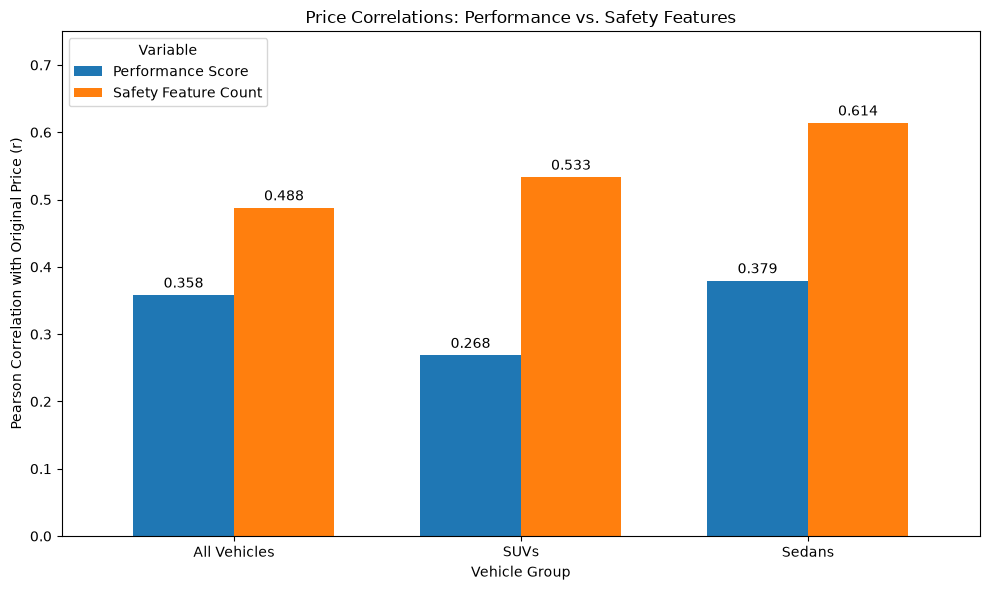

In [15]:

#Calculate correlations for each vehicle group
correlation_results = []

for group_name, group_data in groups.items():
    correlation_results.append({
        "Vehicle Group": group_name,
        "Performance Score": group_data["original_price"].corr(
            group_data["performance_score"]
        ),
        "Safety Feature Count": group_data["original_price"].corr(
            group_data["safety_feature_count"]
        )
    })

#Create a table of correlation results
correlation_df = pd.DataFrame(
    correlation_results
).set_index("Vehicle Group")

#Create a grouped bar chart
fig, ax = plt.subplots(figsize=(10, 6))

correlation_df.plot(
    kind="bar",
    ax=ax,
    width=0.7
)

#Add correlation values above the bars
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)

#Add labels and formatting
ax.set_title("Price Correlations: Performance vs. Safety Features")
ax.set_ylabel("Pearson Correlation with Original Price (r)")
ax.set_xlabel("Vehicle Group")
ax.set_ylim(0, 0.75)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Variable")

plt.tight_layout()
plt.show()



### Findings: Performance and Safety Features

Both performance score and safety feature count show positive
correlations with original vehicle price.

Across all vehicles, safety feature count has a stronger
correlation with price (r = 0.488) than performance score
(r = 0.358).

This pattern also appears when SUVs and sedans are examined
separately. Sedans have the strongest safety feature correlation
(r = 0.614), followed by SUVs (r = 0.533).

Performance score has a weaker relationship with price,
particularly among SUVs (r = 0.268).

These results suggest that higher-priced vehicles tend to have
more listed safety features and higher performance scores.
However, correlation does not establish causation.

Brand, model, equipment level, and other vehicle characteristics
may influence these relationships. Additionally, safety feature
count does not measure actual vehicle safety performance.



## 4. Overall Conclusions and Limitations

Our analysis found noticeable differences in median original
prices across the 13 car brands in the AutoMetrics dataset.

Mercedes-Benz had the highest median price overall and remained
the highest-priced brand when SUVs and sedans were compared
separately. This indicates that differences in body type alone
do not account for the observed brand-price gaps.

We also found positive relationships between price, performance
score, and safety feature count. Safety feature count showed
a stronger linear association with price across the groups
examined.

### Limitations

- The analysis identifies associations, not causal relationships.
- Vehicles within the same body type may still differ in model,
  equipment, age, and performance.
- Some missing original prices were filled using median values
  during data cleaning, which may affect the results.
- Safety feature count measures listed features, not verified
  safety ratings.
- The dataset's pricing units and collection methodology have
  not been independently confirmed.

Overall, the findings show that vehicle pricing differs by
brand and is associated with certain vehicle characteristics.
Further analysis would be needed to determine how much each
factor independently contributes to pricing.
